# Week 1: Returns and Risk
Pull ten years of daily data for both assets and compute daily returns from the **Adjusted Close** price.

In [4]:
# Load your data from ../data/ (see the setup notebook)
from pathlib import Path
import pandas as pd

data_dir = Path("../data")

# Use a fixed 10-year window so results stay consistent when you rerun the notebook.
start_date = "2016-01-01"
end_date = "2025-12-31"

prices = {}

for ticker in ["GLD", "TIP"]:
    df = pd.read_csv(data_dir / f"{ticker}.csv", parse_dates=["Date"])
    df = df.set_index("Date").sort_index()
    prices[ticker] = df.loc[start_date:end_date, "Adj Close"]

# Keep dates available for both assets, then calculate each day's price change.
adjusted_close = pd.concat(prices, axis=1).dropna()
daily_returns = adjusted_close.pct_change().dropna()

daily_returns.head()

,GLD,TIP
Date,,
2016-01-05,0.002819,-0.000635
2016-01-06,0.014441,0.003181
2016-01-07,0.014140,-0.000815
2016-01-08,-0.004428,0.000816
2016-01-11,-0.008895,-0.005254


## Visual
A single chart showing **cumulative log-scale returns** for both assets on the same axes.

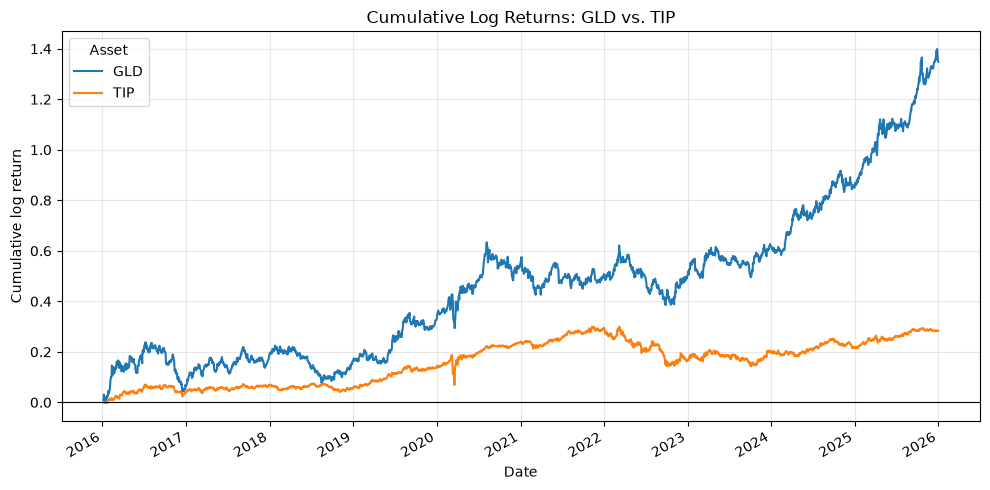

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Add up daily log returns to get cumulative log returns
cumulative_log_returns = np.log1p(daily_returns).cumsum()

ax = cumulative_log_returns.plot(figsize=(10, 5))
ax.set_title("Cumulative Log Returns: GLD vs. TIP")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative log return")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(True, alpha=0.3)
ax.legend(title="Asset")

plt.tight_layout()
plt.show()

## Table
Side-by-side comparison of **annualized return, annualized volatility, and maximum drawdown**.

In [6]:
trading_days_per_year = 252

# Growth of $1 invested, based on daily returns
growth = (1 + daily_returns).cumprod()

annualized_return = growth.iloc[-1] ** (
    trading_days_per_year / len(daily_returns)
) - 1

annualized_volatility = (
    daily_returns.std() * trading_days_per_year**0.5
)

drawdown = growth / growth.cummax() - 1
maximum_drawdown = drawdown.min()

summary = pd.DataFrame({
    "Annualized return": annualized_return,
    "Annualized volatility": annualized_volatility,
    "Maximum drawdown": maximum_drawdown,
})

summary.apply(lambda column: column.map(lambda value: f"{value:.2%}"))

,Annualized return,Annualized volatility,Maximum drawdown
GLD,14.48%,14.80%,-22.00%
TIP,2.88%,5.78%,-14.51%


## Context
Find the **five best and five worst days** for each asset, then look up the news to see what caused them.

GLD Best Days 
| Asset | Date | Return | What happened |
|---|---|---|---|
| GLD | 02/11/2016 | +4.16% | Global panic over negative interest rates |
| GLD | 06/24/2016 | +4.91% | The surprise Brexit referendum causes economic panic in Europe, investors flee to safe investments. |
| GLD | 06/20/2019 | +3.61% | Fed pivots to cutting interest rates, predicting lower real yields and driving up GLD purchasing |
| GLD | 03/23/2020 | +4.42% | The Fed's first pandemic liquidity injection weakens US dollar | 
| GLD | 03/24/2020 | +4.85% | The Fed announces "open ended Quantitative Easing", with near 0% interest rates, Fed issues digital currency, buys back bonds, which forces liquidity, but tanks real yield. |


GLD Worst Days
| Asset | Date | Return | What happened |
|---|---|---|---|
| GLD | 02/28/2020 | -3.53% | Early Covid. Institutions forced to liquidate GLD to cover equity losses. |
| GLD | 03/12/2020 | -3.59% | Systematic liquidations. S&P 500 triggered emergency circuit breakers, sell everything panic. |
| GLD | 03/13/2020 | -4.78% | COVID-19- Investors needed to liquidate in an emergency |
| GLD | 08/11/2020 | -5.65%  | Spike in 10 year bond values: GLD pulled back in order to invest in nominal treasury bonds, favored because of economic optimism with the first vaccine news. |
| GLD | 10/21/2025 | -6.38% | Perfect storm: After massive gains in the year, institutional traders sell, with talks of increased US-China trading, risk apetites increased, and the second largest gold buying market, India, closed for a local holiday. |

TIP Best Days
| Asset | Date | Return | What happened |
|---|---|---|---|
| TIP | 03/04/2020 | +1.85% | Fed lowers interest rates as emergency COVID intervention. |
| TIP | 03/09/2020 | +2.15% | Oil price crash causes flight to safe investments | 
| TIP | 03/19/2020 | +3.42% | Reaction to the "Dash for cash" crisis. Foreign investors desperate for USD, Fed opens global swap lines to trade foreign currency for USD directly with the fed, eliminating need to sell bonds. Predicted long term inflation released, with pandemic low interest rates make negative real yield, causing TIPs buying flood. |
| TIP | 03/24/2020 | +2.84% | QE announcements, flee to safe investments |
| TIP | 11/10/2022 | +1.76% | Cool CPI, which predicts lower interest rates, which increases the value of existing bonds |

TIP Worst Days
| Asset | Date | Return | What happened | 
|---|---|---|---|
| TIP | 03/12/2020 | -1.95% | Pandemic liquidations across all assets |
| TIP | 03/17/2020 | -2.38% | "Dash for Cash", hedges could not meet margin calls in light of the pandemic, so they liquified bonds. The massive flood of bonds meant that banks could not buy them all, so value tanked. | |
| TIP | 03/18/2020 | -2.11% | Liquidity stress before pandemic economic relief. | 
| TIP | 06/13/2022 | -1.88% | Release of data shows the 8.6% year over year inflation, investors predict Fed increasing interest rates. |
| TIP | 09/13/2022 | -1.62% | Hot August CPI, which predicts the fed raising interest rates, whichh deincentivises bond purchasing. | 


## The Paragraph
> **Which asset is actually riskier, and does taking on that extra risk result in a higher return?**

Looking at these tables, it might be easy to say that GLD has higher highs and much lower lows, and thus is riskier. In a stable economy, that certainly is true. Gold thrives on economic instability, with no dividend and no incentive to hold save for its percieved value, it can be a tougher investment than TIPs. TIPs weakness is seen in periods of high expected inflation and even higher interest rate hikes, where real yield is positive and TIP values can drop significantly. Good news; your TIP bond will never fall below its purchase price, and if instead you choose TIP ETF, it still suffers minimal losses on bad days. Your gold, if you bought on the wrong day, can plummet dramatically. The extra risk of buying gold might just be worth it however if you predict widespread economic pessimism in the near future, in which case you can expect your investment to increase dramatically. 

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 1: returns and risk"
git push
```